# Dataset EDA and integrity checks

All image-level checks scan the **entire** training tree (`hackathon_dataset/train`,
i.e. both `train/real` and `train/fake`), not a single class folder. Every check is
reported per class and for the combined set: image count, resolution, format/mode,
and duplicate content hashes. The unlabelled test set and `sample_submission.csv`
are validated at the end.

In [1]:
import hashlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

ROOT = Path.cwd()
DATASET_DIR = ROOT / "hackathon_dataset"
TRAIN_DIR = DATASET_DIR / "train"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("dataset dir:", DATASET_DIR)
print("exists:", DATASET_DIR.exists())

dataset dir: C:\Users\mdsam\Desktop\deep_ml_hakathon\hackathon_dataset
exists: True


In [2]:
df = pd.read_csv(DATASET_DIR / "train_metadata.csv")

print(df.head())
print(df.shape)
print(df.info())
print("nulls:\n", df.isnull().sum())
print(df.describe())

                               image_id  label
0  3cc33bf4-99af-40a3-b769-75a77dc82c30      0
1  71c66ce2-3f44-44b2-b2a0-8cb0bed7bf23      0
2  2052f46e-fa41-43c1-8ecc-02448bc34f12      0
3  30431c3a-0825-42c8-98dd-765d72e6e8c9      0
4  c3f51edc-00b4-470a-8f41-f663384c1759      0
(7000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  7000 non-null   object
 1   label     7000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 109.5+ KB
None
nulls:
 image_id    0
label       0
dtype: int64
             label
count  7000.000000
mean      0.503143
std       0.500026
min       0.000000
25%       0.000000
50%       1.000000
75%       1.000000
max       1.000000


label
fake (1)    3522
real (0)    3478
Name: count, dtype: int64
label
fake (1)    50.314
real (0)    49.686
Name: proportion, dtype: float64


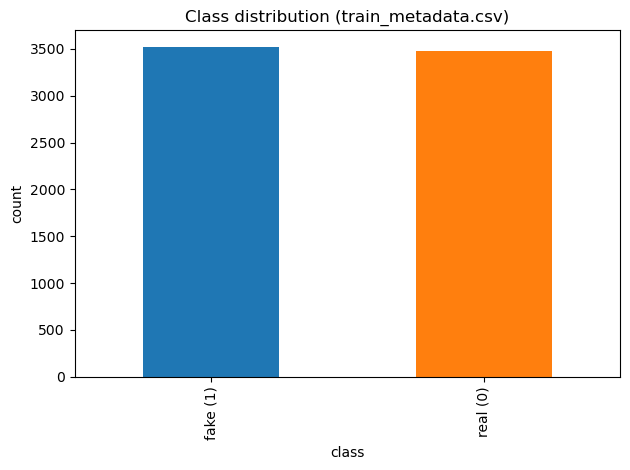

In [3]:
counts = df["label"].value_counts().rename(index={0: "real (0)", 1: "fake (1)"})
shares = (df["label"].value_counts(normalize=True) * 100).round(3)
print(counts)
print(shares.rename(index={0: "real (0)", 1: "fake (1)"}))

ax = counts.plot(kind="bar", color=["tab:blue", "tab:orange"])
ax.set_title("Class distribution (train_metadata.csv)")
ax.set_xlabel("class")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

## Image inventory - both class folders

In [4]:
def list_images(directory: Path) -> list[Path]:
    return sorted(
        path
        for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )


real_files = list_images(TRAIN_DIR / "real")
fake_files = list_images(TRAIN_DIR / "fake")
all_files = list_images(TRAIN_DIR)

print(f"train/real images: {len(real_files)}")
print(f"train/fake images: {len(fake_files)}")
print(f"train/ (recursive, both classes): {len(all_files)}")
print(f"train_metadata.csv rows: {len(df)}")

train/real images: 3478
train/fake images: 3522
train/ (recursive, both classes): 7000
train_metadata.csv rows: 7000


In [5]:
inventory = pd.DataFrame(
    [
        {"split": "real", "label": 0, "images_on_disk": len(real_files), "metadata_rows": int((df["label"] == 0).sum())},
        {"split": "fake", "label": 1, "images_on_disk": len(fake_files), "metadata_rows": int((df["label"] == 1).sum())},
        {"split": "total", "label": None, "images_on_disk": len(all_files), "metadata_rows": len(df)},
    ]
)
print(inventory.to_string(index=False))

assert len(all_files) == len(df), "image count on disk != metadata rows"
assert len(real_files) == int((df["label"] == 0).sum()), "real count mismatch"
assert len(fake_files) == int((df["label"] == 1).sum()), "fake count mismatch"
print("count checks: OK")

split  label  images_on_disk  metadata_rows
 real    0.0            3478           3478
 fake    1.0            3522           3522
total    NaN            7000           7000
count checks: OK


In [6]:
disk_ids = {path.stem for path in all_files}
meta_ids = set(df["image_id"].astype(str))
print("on disk but missing from metadata:", len(disk_ids - meta_ids))
print("in metadata but missing on disk:", len(meta_ids - disk_ids))
print("duplicate metadata image_id rows:", int(df["image_id"].duplicated().sum()))

on disk but missing from metadata: 0
in metadata but missing on disk: 0
duplicate metadata image_id rows: 0


## Resolution - per class and combined

In [7]:
def scan_attribute(files: list[Path], attribute: str) -> list:
    values = []
    for path in files:
        with Image.open(path) as img:
            if attribute == "size":
                values.append(img.size)
            elif attribute == "format":
                values.append(img.format)
            elif attribute == "mode":
                values.append(img.mode)
            else:
                raise ValueError(attribute)
    return values


real_sizes = Counter(scan_attribute(real_files, "size"))
fake_sizes = Counter(scan_attribute(fake_files, "size"))
all_sizes = real_sizes + fake_sizes

print("real resolutions:", real_sizes.most_common(10))
print("fake resolutions:", fake_sizes.most_common(10))
print("combined resolutions:", all_sizes.most_common(10))
print("scanned images:", sum(all_sizes.values()))
print("all images 224x224:", set(all_sizes) == {(224, 224)})

real resolutions: [((224, 224), 3478)]
fake resolutions: [((224, 224), 3522)]
combined resolutions: [((224, 224), 7000)]
scanned images: 7000
all images 224x224: True


## Format and colour mode - per class and combined

In [8]:
format_rows = []
for split, files in (("real", real_files), ("fake", fake_files)):
    for path in files:
        with Image.open(path) as img:
            format_rows.append({"split": split, "format": img.format, "mode": img.mode})

formats = pd.DataFrame(format_rows)
print(formats.groupby(["split", "format", "mode"]).size().rename("images"))
print("\ncombined format counts:")
print(formats["format"].value_counts())
print("\nscanned images:", len(formats))

split  format  mode
fake   JPEG    RGB     3522
real   JPEG    RGB     3478
Name: images, dtype: int64

combined format counts:
format
JPEG    7000
Name: count, dtype: int64

scanned images: 7000


## Duplicate content hashes - whole training tree

MD5 is computed on the raw file bytes, so it catches byte-identical duplicates even
when they live in different class folders.

In [9]:
def md5(path: Path) -> str:
    digest = hashlib.md5()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


hashes: dict[str, list[tuple[str, str]]] = {}
for split, files in (("real", real_files), ("fake", fake_files)):
    for path in files:
        hashes.setdefault(md5(path), []).append((split, path.name))

duplicates = {key: value for key, value in hashes.items() if len(value) > 1}
cross_class = {
    key: value for key, value in duplicates.items() if len({split for split, _ in value}) > 1
}

print("hashed files:", sum(len(value) for value in hashes.values()))
print("duplicate hash groups (whole train tree):", len(duplicates))
print("cross-class duplicate hash groups:", len(cross_class))
for key, entries in list(duplicates.items())[:10]:
    print(key, entries)

hashed files: 7000
duplicate hash groups (whole train tree): 0
cross-class duplicate hash groups: 0


## Test set and submission template

In [10]:
test_files = list_images(DATASET_DIR / "test" / "images")
sample = pd.read_csv(DATASET_DIR / "sample_submission.csv")

print("test images:", len(test_files))
print("sample_submission shape:", sample.shape)
print("sample_submission columns:", sample.columns.tolist())
print("test ids == sample_submission ids:", {p.stem for p in test_files} == set(sample["image_id"].astype(str)))
print("duplicate sample_submission ids:", int(sample["image_id"].duplicated().sum()))
print(sample.head())

test images: 3000
sample_submission shape: (3000, 3)
sample_submission columns: ['image_id', 'label', 'confidence']
test ids == sample_submission ids: True
duplicate sample_submission ids: 0
                               image_id  label  confidence
0  367711e7-e4c2-4a2e-b6ab-1f9d2726fbcd      0         0.5
1  446427b0-a2b9-4fbc-98b8-b4b3f83fb08a      0         0.5
2  c1bb4ef6-1107-465b-83aa-8459e6f0d22f      0         0.5
3  71e01d0a-c2bc-4503-9441-e02f3d42074f      0         0.5
4  6f88ba6b-8443-49b3-82a7-127e1d9a564a      0         0.5


## Summary

- 7,000 labelled crops: 3,478 real / 3,522 fake (49.69 % / 50.31 %).
- The combined `train/` tree contains exactly 7,000 images, matching `train_metadata.csv`;
  the per-class on-disk counts match the metadata label counts.
- Every real and fake image is 224 x 224, JPEG, RGB.
- No duplicate MD5 hashes anywhere in the training tree (0 duplicate groups, 0 cross-class).
- 3,000 unlabelled test images; their file stems match `sample_submission.csv` exactly.
- Because every crop is already a square 224 x 224 face, no face-detection stage is needed.